In [124]:
!pip install scikit-surprise

In [125]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from surprise import Dataset
from surprise import Reader
from surprise import SVD
from surprise import accuracy
from surprise.model_selection import train_test_split

In [127]:
from google.colab import files
uploaded = files.upload()

Saving movies.dat to movies (2).dat
Saving ratings.dat to ratings (2).dat
Saving users.dat to users.dat


In [128]:
ratings = pd.read_csv(
    "ratings.dat",
    sep="::",
    engine="python",
    names=["UserID","MovieID","Rating","Timestamp"]
)

In [129]:
movies = pd.read_csv(
    "movies.dat",
    sep="::",
    engine="python",
    encoding="latin-1",
    names=["MovieID","Title","Genres"]
)

In [148]:
ratings.head()

movies.head()

users = pd.read_csv(
    "users.dat",
    sep="::",
    engine="python",
    names=["UserID","Gender","Age","Occupation","Zip-code"]
)
users.head()

,UserID,Gender,Age,Occupation,Zip-code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


In [149]:
ratings.info()

movies.info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   UserID     1000209 non-null  int64
 1   MovieID    1000209 non-null  int64
 2   Rating     1000209 non-null  int64
 3   Timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   MovieID  3883 non-null   int64 
 1   Title    3883 non-null   object
 2   Genres   3883 non-null   object
dtypes: int64(1), object(2)
memory usage: 91.1+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   UserID      6040 non-null   int64 
 1   Gender      6040 non-null   object
 

In [150]:
ratings.isnull().sum()

movies.isnull().sum()
users.isnull().sum()

,0
UserID,0
Gender,0
Age,0
Occupation,0
Zip-code,0


In [152]:
df = ratings.merge(movies,on="MovieID")
df.head()

,UserID,MovieID,Rating,Timestamp,Title,Genres
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama
1,1,661,3,978302109,James and the Giant Peach (1996),Animation|Children's|Musical
2,1,914,3,978301968,My Fair Lady (1964),Musical|Romance
3,1,3408,4,978300275,Erin Brockovich (2000),Drama
4,1,2355,5,978824291,"Bug's Life, A (1998)",Animation|Children's|Comedy


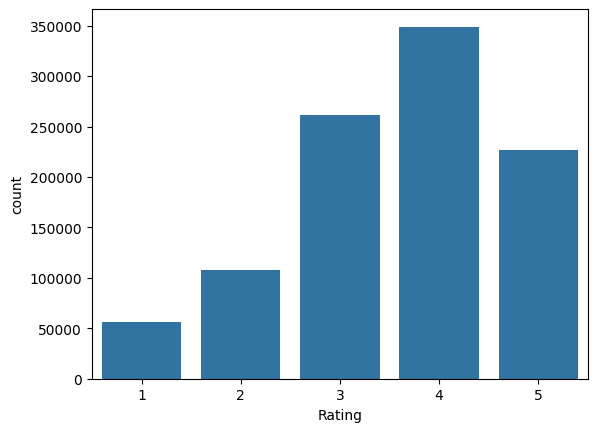

In [153]:
sns.countplot(x='Rating', data=df)

plt.show()

In [154]:
top_movies = df.groupby("Title")["Rating"].mean().sort_values(ascending=False)

top_movies.head(10)

,Rating
Title,
Lured (1947),5.0
Ulysses (Ulisse) (1954),5.0
"Baby, The (1973)",5.0
Follow the Bitch (1998),5.0
Schlafes Bruder (Brother of Sleep) (1995),5.0
Bittersweet Motel (2000),5.0
Song of Freedom (1936),5.0
"Gate of Heavenly Peace, The (1995)",5.0
One Little Indian (1973),5.0


In [155]:
most_rated = df.groupby("Title")["Rating"].count()

most_rated.sort_values(ascending=False).head(10)

,Rating
Title,
American Beauty (1999),3428
Star Wars: Episode IV - A New Hope (1977),2991
Star Wars: Episode V - The Empire Strikes Back (1980),2990
Star Wars: Episode VI - Return of the Jedi (1983),2883
Jurassic Park (1993),2672
Saving Private Ryan (1998),2653
Terminator 2: Judgment Day (1991),2649
"Matrix, The (1999)",2590
Back to the Future (1985),2583


In [156]:
reader = Reader(rating_scale=(1,5))

data = Dataset.load_from_df(
    ratings[['UserID','MovieID','Rating']],
    reader
)

In [157]:
trainset, testset = train_test_split(
    data,
    test_size=0.2,
    random_state=42
)

In [158]:
model = SVD()

model.fit(trainset)

In [159]:
predictions = model.test(testset)

In [160]:
accuracy.rmse(predictions)

RMSE: 0.8744


np.float64(0.8743869446077139)

In [161]:
user_id = 1
movie_id = 50

prediction = model.predict(user_id, movie_id)

print(prediction.est)

4.753485442230275


In [162]:
def recommend_movies(user_id, movies, ratings, model, n=10):

    movie_ids = movies['MovieID'].unique()

    watched = ratings[ratings['UserID']==user_id]['MovieID'].tolist()

    unwatched = [movie for movie in movie_ids if movie not in watched]

    predictions = []

    for movie in unwatched:

        pred = model.predict(user_id, movie)

        predictions.append((movie, pred.est))

    predictions.sort(key=lambda x:x[1], reverse=True)

    recommended = predictions[:n]

    movie_list = []

    for movie, score in recommended:

        title = movies[movies.MovieID==movie]['Title'].values[0]

        movie_list.append([title, round(score,2)])

    return pd.DataFrame(movie_list,
                        columns=['Movie','Predicted Rating'])

In [163]:
recommend_movies(
    user_id=1,
    movies=movies,
    ratings=ratings,
    model=model
)

,Movie,Predicted Rating
0,"Shawshank Redemption, The (1994)",5.00
1,"Great Escape, The (1963)",4.87
2,Sanjuro (1962),4.83
3,"Sting, The (1973)",4.83
4,Braveheart (1995),4.80
5,American History X (1998),4.80
6,"Godfather, The (1972)",4.78
7,Yojimbo (1961),4.77
8,12 Angry Men (1957),4.77
9,Inherit the Wind (1960),4.77


In [164]:
import pickle

pickle.dump(model, open("movie_recommender.pkl","wb"))

In [165]:
model = pickle.load(open("movie_recommender.pkl","rb"))

In [166]:
movie_stats = df.groupby("Title").agg(
    Average_Rating=("Rating", "mean"),
    Number_of_Ratings=("Rating", "count")
)

movie_stats.head()

,Average_Rating,Number_of_Ratings
Title,,
"$1,000,000 Duck (1971)",3.027027,37
'Night Mother (1986),3.371429,70
'Til There Was You (1997),2.692308,52
"'burbs, The (1989)",2.910891,303
...And Justice for All (1979),3.713568,199


In [167]:
popular_movies = movie_stats[
    movie_stats["Number_of_Ratings"] >= 100
].sort_values(
    by="Average_Rating",
    ascending=False
)

popular_movies.head(20)

,Average_Rating,Number_of_Ratings
Title,,
Seven Samurai (The Magnificent Seven) (Shichinin no samurai) (1954),4.560510,628
"Shawshank Redemption, The (1994)",4.554558,2227
"Godfather, The (1972)",4.524966,2223
"Close Shave, A (1995)",4.520548,657
"Usual Suspects, The (1995)",4.517106,1783
Schindler's List (1993),4.510417,2304
"Wrong Trousers, The (1993)",4.507937,882
Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),4.491489,470
Raiders of the Lost Ark (1981),4.477725,2514


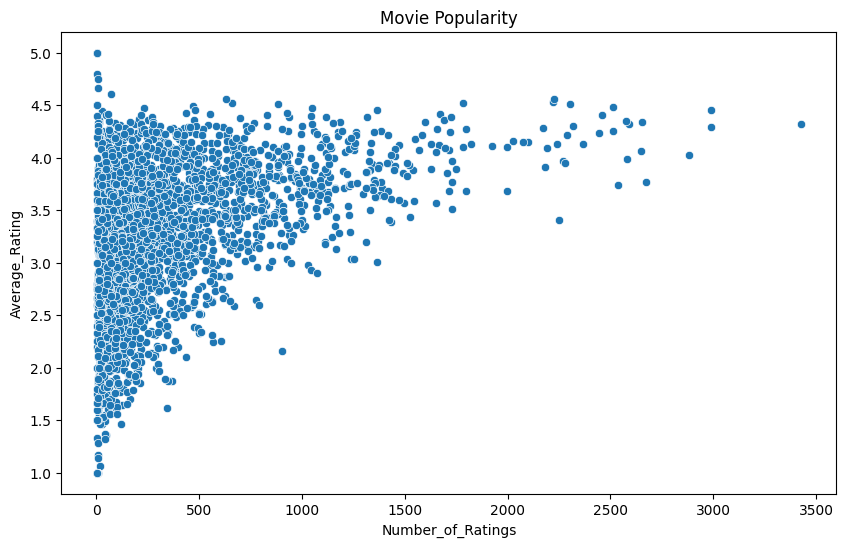

In [168]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=movie_stats,
    x="Number_of_Ratings",
    y="Average_Rating"
)

plt.title("Movie Popularity")
plt.show()

In [169]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words='english')

movies["Genres"] = movies["Genres"].fillna("")

tfidf_matrix = tfidf.fit_transform(movies["Genres"])

In [170]:
from sklearn.metrics.pairwise import cosine_similarity

cosine_sim = cosine_similarity(tfidf_matrix)

In [171]:
indices = pd.Series(
    movies.index,
    index=movies["Title"]
).drop_duplicates()

In [172]:
def content_recommend(title, cosine_sim=cosine_sim):

    idx = indices[title]

    similarity_scores = list(enumerate(cosine_sim[idx]))

    similarity_scores = sorted(
        similarity_scores,
        key=lambda x:x[1],
        reverse=True
    )

    similarity_scores = similarity_scores[1:11]

    movie_indices = [i[0] for i in similarity_scores]

    return movies["Title"].iloc[movie_indices]

In [173]:
content_recommend("Toy Story (1995)")

,Title
1050,Aladdin and the King of Thieves (1996)
2072,"American Tail, An (1986)"
2073,"American Tail: Fievel Goes West, An (1991)"
2285,"Rugrats Movie, The (1998)"
2286,"Bug's Life, A (1998)"
3045,Toy Story 2 (1999)
3542,Saludos Amigos (1943)
3682,Chicken Run (2000)
3685,"Adventures of Rocky and Bullwinkle, The (2000)"
12,Balto (1995)


In [174]:
movie_matrix = ratings.pivot_table(
    index="UserID",
    columns="MovieID",
    values="Rating"
)

movie_matrix.head()

MovieID,1,2,3,4,5,6,7,8,9,10,...,3943,3944,3945,3946,3947,3948,3949,3950,3951,3952
UserID,,,,,,,,,,,,,,,,,,,,,
1,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [175]:
from sklearn.metrics.pairwise import cosine_similarity

user_similarity = cosine_similarity(
    movie_matrix.fillna(0)
)

user_similarity.shape

(6040, 6040)

In [176]:
movie_similarity = cosine_similarity(
    movie_matrix.fillna(0).T
)

movie_similarity.shape

(3706, 3706)

In [177]:
movie_similarity_df = pd.DataFrame(
    movie_similarity,
    index=movie_matrix.columns,
    columns=movie_matrix.columns
)

In [86]:
def similar_movies(movie_id):

    similar = movie_similarity_df[movie_id]

    similar = similar.sort_values(
        ascending=False
    )

    return similar.head(10)

In [178]:
similar_movies(2)

,2
MovieID,
2,1.000000
3489,0.571704
653,0.501754
60,0.479376
2054,0.478643
2161,0.476649
317,0.475291
367,0.470173
1073,0.459820


In [179]:
user_id_to_predict = 1
movie_id_to_predict = 50
collaborative_score = model.predict(user_id_to_predict, movie_id_to_predict).est
content_score = 0.0
final_score = (
    0.7 * collaborative_score +
    0.3 * content_score
)

In [180]:
from surprise import accuracy

accuracy.rmse(predictions)

RMSE: 0.8744


np.float64(0.8743869446077139)

In [181]:
accuracy.mae(predictions)

MAE:  0.6855


np.float64(0.6854770734691102)

In [182]:
import pickle

pickle.dump(model, open("svd_model.pkl", "wb"))
pickle.dump(cosine_sim, open("cosine.pkl", "wb"))
pickle.dump(movie_similarity_df, open("movie_similarity.pkl", "wb"))

In [183]:
df.head()

,UserID,MovieID,Rating,Timestamp,Title,Genres
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama
1,1,661,3,978302109,James and the Giant Peach (1996),Animation|Children's|Musical
2,1,914,3,978301968,My Fair Lady (1964),Musical|Romance
3,1,3408,4,978300275,Erin Brockovich (2000),Drama
4,1,2355,5,978824291,"Bug's Life, A (1998)",Animation|Children's|Comedy


In [184]:
df.shape

(1000209, 6)

In [185]:
df.isnull().sum()

,0
UserID,0
MovieID,0
Rating,0
Timestamp,0
Title,0
Genres,0


In [186]:
df.duplicated().sum()

np.int64(0)

In [187]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 6 columns):
 #   Column     Non-Null Count    Dtype 
---  ------     --------------    ----- 
 0   UserID     1000209 non-null  int64 
 1   MovieID    1000209 non-null  int64 
 2   Rating     1000209 non-null  int64 
 3   Timestamp  1000209 non-null  int64 
 4   Title      1000209 non-null  object
 5   Genres     1000209 non-null  object
dtypes: int64(4), object(2)
memory usage: 45.8+ MB


In [188]:
df.describe()

,UserID,MovieID,Rating,Timestamp
count,1.000209e+06,1.000209e+06,1.000209e+06,1.000209e+06
mean,3.024512e+03,1.865540e+03,3.581564e+00,9.722437e+08
std,1.728413e+03,1.096041e+03,1.117102e+00,1.215256e+07
min,1.000000e+00,1.000000e+00,1.000000e+00,9.567039e+08
25%,1.506000e+03,1.030000e+03,3.000000e+00,9.653026e+08
50%,3.070000e+03,1.835000e+03,4.000000e+00,9.730180e+08
75%,4.476000e+03,2.770000e+03,4.000000e+00,9.752209e+08
max,6.040000e+03,3.952000e+03,5.000000e+00,1.046455e+09


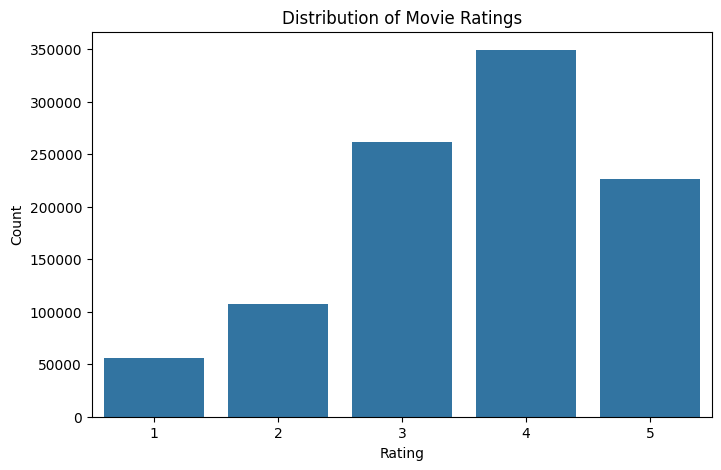

In [189]:
plt.figure(figsize=(8,5))
sns.countplot(x='Rating', data=df)
plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

In [190]:
most_rated = df.groupby("Title")["Rating"].count().sort_values(ascending=False)

most_rated.head(10)

,Rating
Title,
American Beauty (1999),3428
Star Wars: Episode IV - A New Hope (1977),2991
Star Wars: Episode V - The Empire Strikes Back (1980),2990
Star Wars: Episode VI - Return of the Jedi (1983),2883
Jurassic Park (1993),2672
Saving Private Ryan (1998),2653
Terminator 2: Judgment Day (1991),2649
"Matrix, The (1999)",2590
Back to the Future (1985),2583


In [191]:
movie_stats = df.groupby("Title").agg(
    Average_Rating=("Rating", "mean"),
    Number_of_Ratings=("Rating", "count")
)

top_movies = movie_stats[movie_stats["Number_of_Ratings"] >= 100] \
    .sort_values("Average_Rating", ascending=False)

top_movies.head(10)

,Average_Rating,Number_of_Ratings
Title,,
Seven Samurai (The Magnificent Seven) (Shichinin no samurai) (1954),4.560510,628
"Shawshank Redemption, The (1994)",4.554558,2227
"Godfather, The (1972)",4.524966,2223
"Close Shave, A (1995)",4.520548,657
"Usual Suspects, The (1995)",4.517106,1783
Schindler's List (1993),4.510417,2304
"Wrong Trousers, The (1993)",4.507937,882
Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),4.491489,470
Raiders of the Lost Ark (1981),4.477725,2514


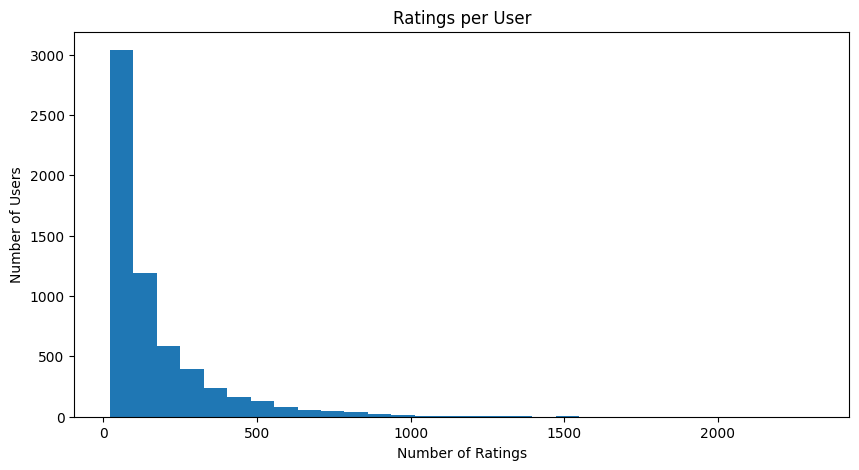

In [192]:
user_ratings = df.groupby("UserID")["Rating"].count()

plt.figure(figsize=(10,5))
plt.hist(user_ratings, bins=30)
plt.title("Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.show()

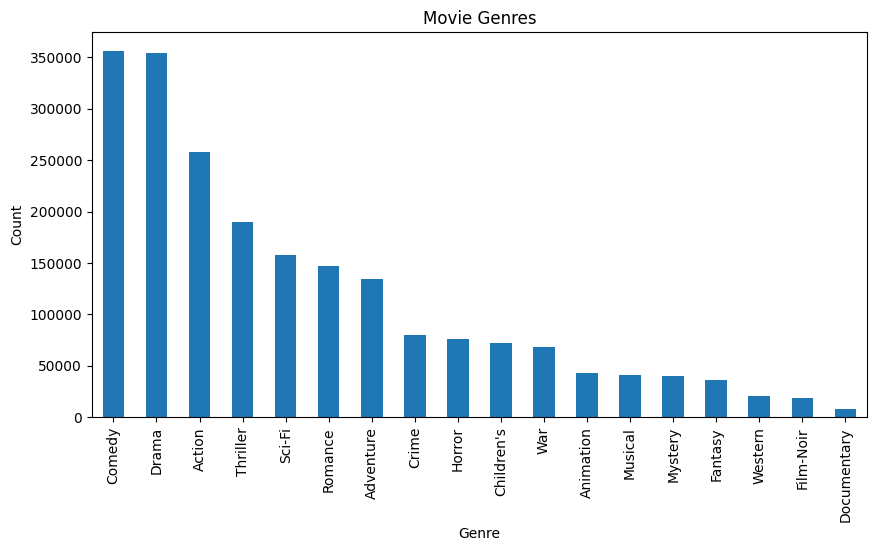

In [193]:
genres = df["Genres"].str.split("|").explode()

genres.value_counts().plot(kind="bar", figsize=(10,5))

plt.title("Movie Genres")
plt.xlabel("Genre")
plt.ylabel("Count")
plt.show()

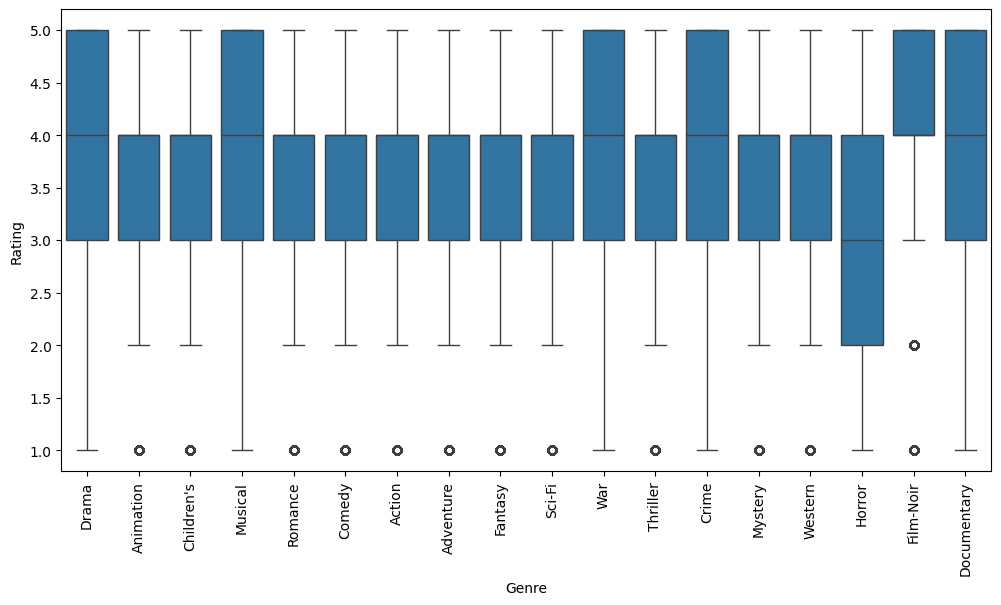

In [194]:
genre_df = df.copy()
genre_df["Genre"] = genre_df["Genres"].str.split("|")
genre_df = genre_df.explode("Genre")

plt.figure(figsize=(12,6))
sns.boxplot(x="Genre", y="Rating", data=genre_df)
plt.xticks(rotation=90)
plt.show()

In [195]:
movie_stats = df.groupby("Title").agg(
    Average_Rating=("Rating", "mean"),
    Number_of_Ratings=("Rating", "count")
).reset_index()

movie_stats.head()

,Title,Average_Rating,Number_of_Ratings
0,"$1,000,000 Duck (1971)",3.027027,37
1,'Night Mother (1986),3.371429,70
2,'Til There Was You (1997),2.692308,52
3,"'burbs, The (1989)",2.910891,303
4,...And Justice for All (1979),3.713568,199


In [196]:
popular_movies = movie_stats[movie_stats["Number_of_Ratings"] >= 100]

In [197]:
popular_movies = popular_movies.sort_values(
    by="Average_Rating",
    ascending=False
)

popular_movies.head(10)

,Title,Average_Rating,Number_of_Ratings
2940,Seven Samurai (The Magnificent Seven) (Shichin...,4.560510,628
2970,"Shawshank Redemption, The (1994)",4.554558,2227
1354,"Godfather, The (1972)",4.524966,2223
713,"Close Shave, A (1995)",4.520548,657
3504,"Usual Suspects, The (1995)",4.517106,1783
2901,Schindler's List (1993),4.510417,2304
3675,"Wrong Trousers, The (1993)",4.507937,882
3218,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),4.491489,470
2711,Raiders of the Lost Ark (1981),4.477725,2514
2738,Rear Window (1954),4.476190,1050


In [198]:
def popularity_recommendations(n=10):
    return popular_movies[
        ["Title", "Average_Rating", "Number_of_Ratings"]
    ].head(n)

In [199]:
popularity_recommendations()

,Title,Average_Rating,Number_of_Ratings
2940,Seven Samurai (The Magnificent Seven) (Shichin...,4.560510,628
2970,"Shawshank Redemption, The (1994)",4.554558,2227
1354,"Godfather, The (1972)",4.524966,2223
713,"Close Shave, A (1995)",4.520548,657
3504,"Usual Suspects, The (1995)",4.517106,1783
2901,Schindler's List (1993),4.510417,2304
3675,"Wrong Trousers, The (1993)",4.507937,882
3218,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),4.491489,470
2711,Raiders of the Lost Ark (1981),4.477725,2514
2738,Rear Window (1954),4.476190,1050


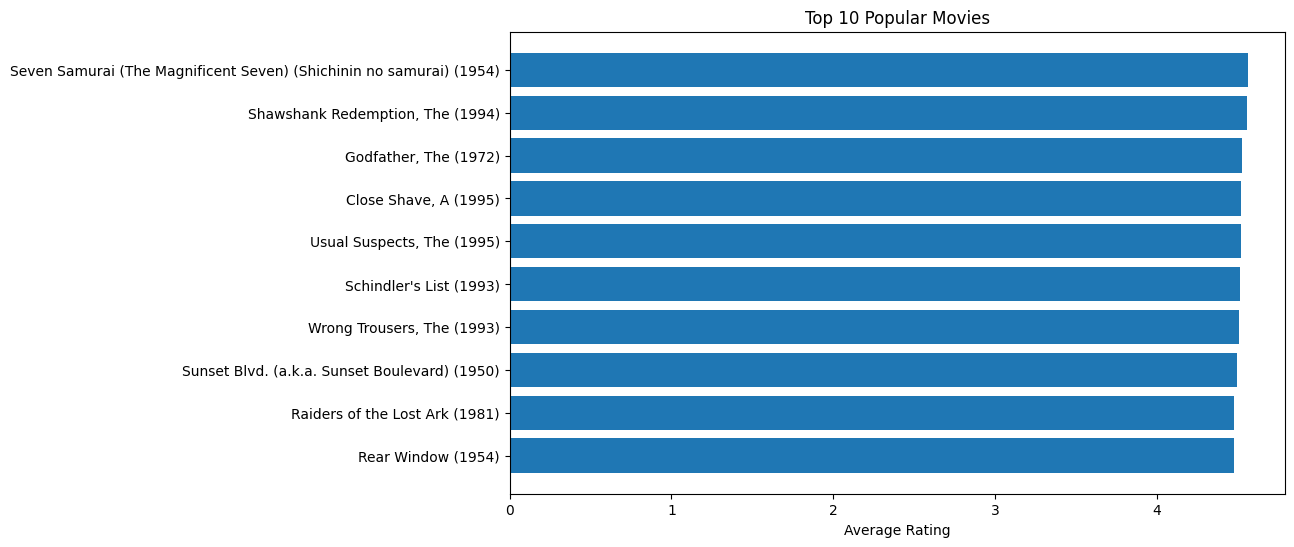

In [200]:
import matplotlib.pyplot as plt

top10 = popularity_recommendations(10)

plt.figure(figsize=(10,6))
plt.barh(top10["Title"], top10["Average_Rating"])
plt.xlabel("Average Rating")
plt.title("Top 10 Popular Movies")
plt.gca().invert_yaxis()
plt.show()

In [201]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [202]:
movies["Genres"] = movies["Genres"].fillna("")
movies.head()

,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [203]:
tfidf = TfidfVectorizer()

tfidf_matrix = tfidf.fit_transform(movies["Genres"])

print(tfidf_matrix.shape)

(3883, 20)


In [204]:
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

print(cosine_sim.shape)

(3883, 3883)


In [205]:
indices = pd.Series(
    movies.index,
    index=movies["Title"]
).drop_duplicates()

In [206]:
def content_recommendations(title, cosine_sim=cosine_sim):

    idx = indices[title]

    sim_scores = list(enumerate(cosine_sim[idx]))

    sim_scores = sorted(
        sim_scores,
        key=lambda x: x[1],
        reverse=True
    )

    sim_scores = sim_scores[1:11]

    movie_indices = [i[0] for i in sim_scores]

    return movies.iloc[movie_indices][["Title", "Genres"]]

In [207]:
content_recommendations("Toy Story (1995)")
content_recommendations("Jumanji (1995)")
content_recommendations("Heat (1995)")
content_recommendations("GoldenEye (1995)")

,Title,Genres
345,Clear and Present Danger (1994),Action|Adventure|Thriller
543,Surviving the Game (1994),Action|Adventure|Thriller
724,"Rock, The (1996)",Action|Adventure|Thriller
788,Daylight (1996),Action|Adventure|Thriller
825,Chain Reaction (1996),Action|Adventure|Thriller
978,Maximum Risk (1996),Action|Adventure|Thriller
1467,Anaconda (1997),Action|Adventure|Thriller
1513,Con Air (1997),Action|Adventure|Thriller
1693,Firestorm (1998),Action|Adventure|Thriller
3686,"Perfect Storm, The (2000)",Action|Adventure|Thriller


In [208]:
user_movie_matrix = ratings.pivot_table(
    index="UserID",
    columns="MovieID",
    values="Rating"
)

user_movie_matrix.head()

MovieID,1,2,3,4,5,6,7,8,9,10,...,3943,3944,3945,3946,3947,3948,3949,3950,3951,3952
UserID,,,,,,,,,,,,,,,,,,,,,
1,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [209]:
print(user_movie_matrix.shape)

(6040, 3706)


In [210]:
user_movie_filled = user_movie_matrix.fillna(0)

In [211]:
from sklearn.metrics.pairwise import cosine_similarity

user_similarity = cosine_similarity(user_movie_filled)

In [212]:
user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_movie_matrix.index,
    columns=user_movie_matrix.index
)

In [213]:
similar_users = user_similarity_df[1].sort_values(ascending=False)

similar_users.head(10)

,1
UserID,
1,1.000000
5343,0.412117
5190,0.411899
1481,0.392110
1283,0.386597
5705,0.360898
5762,0.355600
1359,0.350329
1476,0.339496


In [214]:
similar_users = similar_users.drop(1)

similar_users.head(10)

,1
UserID,
5343,0.412117
5190,0.411899
1481,0.392110
1283,0.386597
5705,0.360898
5762,0.355600
1359,0.350329
1476,0.339496
541,0.334864


In [217]:
user_ratings_count = ratings.groupby("UserID")["Rating"].count()
top_users_ids = user_ratings_count[user_ratings_count >= 100].index

ratings[
    ratings["UserID"].isin(top_users_ids)
].head()

,UserID,MovieID,Rating,Timestamp
53,2,1357,5,978298709
54,2,3068,4,978299000
55,2,1537,4,978299620
56,2,647,3,978299351
57,2,2194,4,978299297


In [218]:
ratings["UserID"].nunique()
ratings["MovieID"].nunique()
similar_users.head(1)

,1
UserID,
5343,0.412117


In [219]:
def recommend_user_based(user_id, top_n=10):

    # Find similar users
    similar_users = user_similarity_df[user_id].sort_values(ascending=False)[1:11]

    # Movies already watched by the user
    watched_movies = ratings[ratings["UserID"] == user_id]["MovieID"].tolist()

    # Ratings from similar users
    similar_users_ratings = ratings[
        ratings["UserID"].isin(similar_users.index)
    ]

    # Remove watched movies
    recommendations = similar_users_ratings[
        ~similar_users_ratings["MovieID"].isin(watched_movies)
    ]

    # Average ratings for each movie
    recommendations = (
        recommendations.groupby("MovieID")["Rating"]
        .mean()
        .sort_values(ascending=False)
    )

    # Top N movie IDs
    top_movie_ids = recommendations.head(top_n).index

    # Get movie titles
    return movies[movies["MovieID"].isin(top_movie_ids)][
        ["MovieID", "Title", "Genres"]
    ]

In [220]:
recommend_user_based(1)


,MovieID,Title,Genres
3229,3298,Boiler Room (2000),Drama
3231,3300,Pitch Black (2000),Action|Sci-Fi
3292,3361,Bull Durham (1988),Comedy
3327,3396,"Muppet Movie, The (1979)",Children's|Comedy
3335,3404,Titanic (1953),Action|Drama
3369,3438,Teenage Mutant Ninja Turtles (1990),Action|Children's|Fantasy
3376,3445,Eyes of Laura Mars (1978),Mystery|Thriller
3379,3448,"Good Morning, Vietnam (1987)",Comedy|Drama|War
3381,3450,Grumpy Old Men (1993),Comedy
3420,3489,Hook (1991),Adventure|Fantasy


In [221]:
recommend_user_based(10)
recommend_user_based(100)
recommend_user_based(500)

,MovieID,Title,Genres
28,29,"City of Lost Children, The (1995)",Adventure|Sci-Fi
159,161,Crimson Tide (1995),Drama|Thriller|War
211,213,Burnt By the Sun (Utomlyonnye solntsem) (1994),Drama
258,261,Little Women (1994),Drama
1844,1913,Picnic at Hanging Rock (1975),Drama|Mystery
1885,1954,Rocky (1976),Action|Drama
3457,3526,Parenthood (1989),Comedy|Drama
3474,3543,Diner (1982),Comedy|Drama
3599,3668,Romeo and Juliet (1968),Drama|Romance
3732,3801,Anatomy of a Murder (1959),Drama|Mystery


In [223]:
movie_user_matrix = ratings.pivot_table(
    index="MovieID",
    columns="UserID",
    values="Rating"
)

movie_user_matrix.head()
print(movie_user_matrix.shape)

(3706, 6040)


In [224]:
movie_user_filled = movie_user_matrix.fillna(0)

In [225]:
from sklearn.metrics.pairwise import cosine_similarity

movie_similarity = cosine_similarity(movie_user_filled)

In [226]:
movie_similarity_df = pd.DataFrame(
    movie_similarity,
    index=movie_user_matrix.index,
    columns=movie_user_matrix.index
)

In [227]:
def similar_movies(movie_id, top_n=10):

    similar = movie_similarity_df[movie_id].sort_values(
        ascending=False
    )

    similar = similar.iloc[1:top_n+1]

    result = movies[movies["MovieID"].isin(similar.index)][
        ["MovieID", "Title", "Genres"]
    ].copy()

    result["Similarity"] = result["MovieID"].map(similar)

    return result.sort_values("Similarity", ascending=False)

In [228]:
movies[movies["Title"] == "Toy Story (1995)"]
similar_movies(1)

,MovieID,Title,Genres,Similarity
3045,3114,Toy Story 2 (1999),Animation|Children's|Comedy,0.633104
1245,1265,Groundhog Day (1993),Comedy|Romance,0.610826
584,588,Aladdin (1992),Animation|Children's|Comedy|Musical,0.605849
2286,2355,"Bug's Life, A (1998)",Animation|Children's|Comedy,0.579382
1250,1270,Back to the Future (1985),Comedy|Sci-Fi,0.570125
33,34,Babe (1995),Children's|Comedy|Drama,0.563637
1178,1196,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War,0.552856
1539,1580,Men in Black (1997),Action|Adventure|Comedy|Sci-Fi,0.552362
352,356,Forrest Gump (1994),Comedy|Romance|War,0.551034
2502,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,0.550294


In [229]:
from surprise import accuracy

accuracy.rmse(predictions)
accuracy.mae(predictions)

RMSE: 0.8744
MAE:  0.6855


np.float64(0.6854770734691102)

In [230]:
import pickle

pickle.dump(model, open("svd_model.pkl", "wb"))
pickle.dump(cosine_sim, open("content_model.pkl", "wb"))
pickle.dump(movie_similarity_df, open("item_similarity.pkl", "wb"))